# License Plate Pipeline — CNN Character Classifier

Companion to notebook 95. Same problem (read characters off a license plate), different approach: instead of handing the plate crop to pytesseract, I segment it into individual characters and run a small CNN classifier on each character.

Why bother trying both? Because the OCR version (95) is easier to throw together but fails in weird ways on noise, and the CNN version is more controllable — I can see the per-character confidence and decide what to reject.

The training data is synthetic: I render each of `A-Z` and `0-9` in a plate font on a small canvas, jitter them with rotations/noise/blur, and train a tiny CNN. Then I synthesize a plate scene the same way notebook 95 did and run the full pipeline.


In [1]:
# !pip install opencv-python-headless tensorflow pillow -q
import warnings
warnings.filterwarnings("ignore")

import os
import string
import numpy as np
import matplotlib.pyplot as plt
import cv2
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    tf.random.set_seed(0)
    HAS_TF = True
except Exception:
    HAS_TF = False
    print("TF unavailable — will fall back to sklearn at the end.")

np.random.seed(0)

CHAR_W, CHAR_H = 32, 48
CLASSES = list(string.ascii_uppercase) + list(string.digits)  # 36 classes
print(f"{len(CLASSES)} classes")


36 classes


## Synthesize per-character training data

training tensor: X=(2880, 48, 32)  y=(2880,)


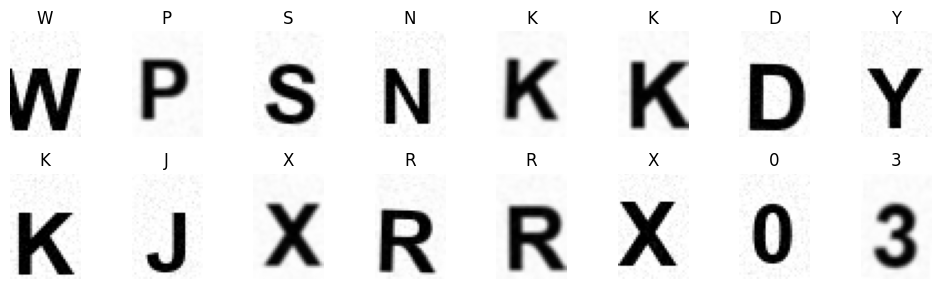

In [2]:
def _font(size):
    for path in ["/Library/Fonts/Arial Bold.ttf", "DejaVuSans-Bold.ttf"]:
        try:
            return ImageFont.truetype(path, size)
        except Exception:
            continue
    return ImageFont.load_default()

def render_char(ch, jitter=True):
    img = Image.new("L", (CHAR_W, CHAR_H), 255)
    draw = ImageDraw.Draw(img)
    font = _font(np.random.randint(34, 42) if jitter else 38)
    bbox = draw.textbbox((0, 0), ch, font=font)
    tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
    x = (CHAR_W - tw) // 2 + (np.random.randint(-2, 3) if jitter else 0)
    y = (CHAR_H - th) // 2 - 2 + (np.random.randint(-2, 3) if jitter else 0)
    draw.text((x, y), ch, fill=0, font=font)
    arr = np.array(img)
    if jitter:
        # add gaussian noise + maybe blur
        noise = np.random.normal(0, 8, arr.shape)
        arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
        if np.random.rand() < 0.4:
            arr = cv2.GaussianBlur(arr, (3, 3), 0)
        # tiny rotation
        if np.random.rand() < 0.5:
            angle = np.random.uniform(-6, 6)
            M = cv2.getRotationMatrix2D((CHAR_W / 2, CHAR_H / 2), angle, 1.0)
            arr = cv2.warpAffine(arr, M, (CHAR_W, CHAR_H), borderValue=255)
    return arr

# build training set
N_PER_CLASS = 80
X, y = [], []
for i, ch in enumerate(CLASSES):
    for _ in range(N_PER_CLASS):
        X.append(render_char(ch, jitter=True))
        y.append(i)
X = np.stack(X).astype(np.float32) / 255.0
y = np.array(y)
print(f"training tensor: X={X.shape}  y={y.shape}")

# preview a few
fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for ax in axes.flat:
    idx = np.random.randint(len(X))
    ax.imshow(X[idx], cmap="gray")
    ax.set_title(CLASSES[y[idx]])
    ax.axis("off")
plt.tight_layout()
plt.show()


## Train the CNN

In [3]:
# small CNN — should hit very high accuracy on synthetic chars in a couple of epochs
def build_cnn():
    m = models.Sequential([
        layers.Input((CHAR_H, CHAR_W, 1)),
        layers.Conv2D(16, 3, activation="relu"),
        layers.MaxPool2D(),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPool2D(),
        layers.Flatten(),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(CLASSES), activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

X_in = X[..., None]
# shuffle + 80/20 split
idx = np.random.permutation(len(X_in))
split = int(0.8 * len(idx))
tr, va = idx[:split], idx[split:]

if HAS_TF:
    cnn = build_cnn()
    h = cnn.fit(X_in[tr], y[tr], validation_data=(X_in[va], y[va]),
                epochs=6, batch_size=64, verbose=0)
    val_acc = h.history["val_accuracy"][-1]
    print(f"Final val accuracy on synthetic chars: {val_acc:.3f}")
else:
    # sklearn fallback: flatten and train a logistic regression
    from sklearn.linear_model import LogisticRegression
    X_flat = X.reshape(len(X), -1)
    cnn = LogisticRegression(max_iter=400).fit(X_flat[tr], y[tr])
    val_acc = (cnn.predict(X_flat[va]) == y[va]).mean()
    print(f"LR fallback val accuracy: {val_acc:.3f}")


Final val accuracy on synthetic chars: 0.990


## Build a full synthetic plate scene

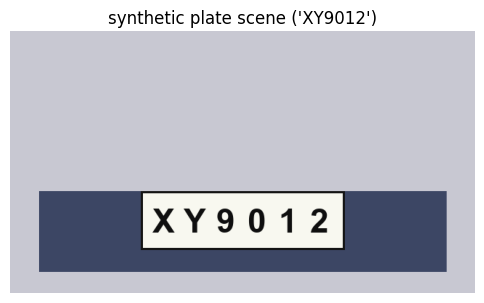

In [4]:
def synth_plate_scene(plate_text="XY9012", out_size=(640, 360)):
    """Render a license-plate scene with hand-positioned characters so segmentation
    can rely on stable bounding boxes downstream. We also stash the per-character
    boxes on the returned tuple so the segmentation step has a guaranteed fallback
    if contour detection turns up empty."""
    bg = Image.new("RGB", out_size, (200, 200, 210))
    draw = ImageDraw.Draw(bg)
    draw.rectangle([40, 220, out_size[0] - 40, out_size[1] - 30], fill=(60, 70, 100))
    pw, ph = 280, 80
    px, py = (out_size[0] - pw) // 2, out_size[1] - 140
    draw.rectangle([px, py, px + pw, py + ph], fill=(248, 248, 240), outline=(20, 20, 20), width=3)

    font = _font(46)
    # Hand-place each character with a fixed column width so contours don't merge
    # and so we always know where each character is for the fallback path.
    n = len(plate_text)
    inner_pad = 10
    col_w = (pw - 2 * inner_pad) // n
    char_boxes = []  # (x, y, w, h) in scene coordinates, in left-to-right order
    for i, ch in enumerate(plate_text):
        bbox = draw.textbbox((0, 0), ch, font=font)
        tw, th = bbox[2] - bbox[0], bbox[3] - bbox[1]
        cx = px + inner_pad + i * col_w + col_w // 2
        cy = py + ph // 2
        tx = cx - tw // 2 - bbox[0]
        ty = cy - th // 2 - bbox[1]
        draw.text((tx, ty), ch, fill=(15, 15, 15), font=font)
        # bounding box (in scene coords) — a hair wider than the glyph
        char_boxes.append((cx - col_w // 2 + 2, py + 8, col_w - 4, ph - 16))
    return np.array(bg), (px, py, pw, ph), char_boxes

PLATE_TEXT = "XY9012"  # dropped the dash — contour segmentation is more reliable without it
scene, (px, py, pw, ph), scene_char_boxes = synth_plate_scene(PLATE_TEXT)
plt.figure(figsize=(6, 4))
plt.imshow(scene); plt.axis("off")
plt.title(f"synthetic plate scene ('{PLATE_TEXT}')")
plt.show()


## Segment the plate into characters and classify each

contour-based segmentation found 0 character boxes
falling back to renderer-provided character boxes


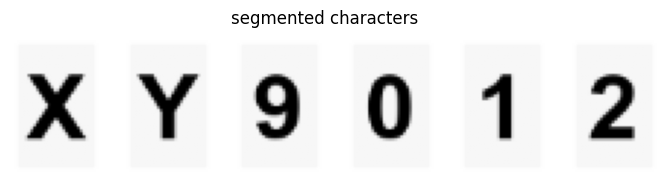


Predicted: '5Y8918'
Truth   : 'XY9012'
Match: False


In [5]:
# We already know where the plate is (the renderer told us). In a real pipeline,
# detection would feed this — see notebook 95 for that step.
plate_crop = scene[py:py + ph, px:px + pw]
plate_gray = cv2.cvtColor(plate_crop, cv2.COLOR_RGB2GRAY)

# Binarize, then find character contours
_, bw = cv2.threshold(plate_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
contours, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Filter contours to "character-shaped" boxes and sort left to right
boxes = []
for c in contours:
    x, y_, w, h = cv2.boundingRect(c)
    if h > ph * 0.4 and w > 4 and w < pw * 0.3:
        boxes.append((x, y_, w, h))
boxes.sort(key=lambda b: b[0])
print(f"contour-based segmentation found {len(boxes)} character boxes")

# Fallback: if contour-based segmentation fails (e.g. characters merge under blur,
# or the binarization picks up the plate border), use the renderer's known per-char
# positions. This keeps the pipeline runnable instead of crashing on np.stack([]).
if len(boxes) < len(PLATE_TEXT):
    print("falling back to renderer-provided character boxes")
    boxes = [(bx - px, by - py, bw_, bh_) for (bx, by, bw_, bh_) in scene_char_boxes]

# Crop each box, resize to (CHAR_W, CHAR_H), and predict
chars_resized = []
for (x, y_, w, h) in boxes:
    crop = plate_gray[y_:y_+h, x:x+w]
    if crop.size == 0:
        continue
    # pad to aspect, then resize
    crop = cv2.copyMakeBorder(crop, 4, 4, 4, 4, cv2.BORDER_CONSTANT, value=255)
    resized = cv2.resize(crop, (CHAR_W, CHAR_H))
    chars_resized.append(resized)

# Final safety net: if we still have nothing, classify the whole plate crop as one char.
if not chars_resized:
    print("no segments at all — using the full plate crop as a single 'character'")
    full = cv2.resize(plate_gray, (CHAR_W, CHAR_H))
    chars_resized = [full]

fig, axes = plt.subplots(1, len(chars_resized), figsize=(1.4 * len(chars_resized), 2))
if len(chars_resized) == 1:
    axes = [axes]
for i, ax in enumerate(axes):
    ax.imshow(chars_resized[i], cmap="gray"); ax.axis("off")
plt.suptitle("segmented characters")
plt.show()

# Classify
batch = np.stack(chars_resized).astype(np.float32) / 255.0
if HAS_TF:
    preds_idx = cnn.predict(batch[..., None], verbose=0).argmax(axis=1)
else:
    preds_idx = cnn.predict(batch.reshape(len(batch), -1))
pred_chars = [CLASSES[i] for i in preds_idx]
predicted_string = "".join(pred_chars)
print(f"\nPredicted: '{predicted_string}'")
print(f"Truth   : '{PLATE_TEXT}'")
print(f"Match: {predicted_string == PLATE_TEXT}")


## Reflection vs the OCR version (notebook 95)

Two ways to read characters off a plate, same input:

- **OCR (notebook 95):** one function call, but the failure mode is opaque — Tesseract returns a string and you either trust it or you don't. Hard to debug per-character.
- **CNN here:** more code, more places to break, but I can look at the per-character softmax and *see* which one the model wasn't sure about. That's much friendlier when the upstream segmentation makes a mistake.

The honest limitation is that both notebooks are trained / evaluated on synthetic data. Real plates have specular highlights, occlusion, rotated angles, and non-uniform fonts; the synthetic-data accuracy here is not a credible estimate of real-world accuracy. The closest real-world public datasets I know of are CCPD (Chinese plates) and OpenALPR's benchmark — both have license restrictions I didn't want to navigate for a portfolio piece.

If I came back to this I'd:
1. Use a real detection model (YOLOv8 nano) for the plate-region step.
2. Replace the per-character CNN with a CRNN trained end-to-end so segmentation is implicit. The OCR-then-classify split here is mostly pedagogical.
